In [1]:

import pandas as pd
import numpy as np

# Enter your Python ground-truth answers from your analysis.
# Enter ChatGPT and Gemini answers manually as well.

data = [
    {"Question": "Mean Maths", "Python_Ground_Truth": 58.20000, "ChatGPT_Answer": 58.20, "Gemini_Answer": 58.20},
    {"Question": "Median Maths", "Python_Ground_Truth": 58.00000, "ChatGPT_Answer": 58, "Gemini_Answer": 58.00},
    {"Question": "Mean Physics", "Python_Ground_Truth": 61.00000, "ChatGPT_Answer": 61.00, "Gemini_Answer": 61.00},
    {"Question": "Mean Chemistry", "Python_Ground_Truth": 77.25000, "ChatGPT_Answer": 77.25, "Gemini_Answer": 77.25},
    {"Question": "Mean English", "Python_Ground_Truth": 67.20000, "ChatGPT_Answer": 67.20, "Gemini_Answer": 67.20},
    {"Question": "Mean Biology", "Python_Ground_Truth": 71.20000, "ChatGPT_Answer": 71.20, "Gemini_Answer": 71.20},
    {"Question": "Mean Economics", "Python_Ground_Truth": 73.20000, "ChatGPT_Answer": 73.20, "Gemini_Answer": 73.20},
    {"Question": "Mean History", "Python_Ground_Truth": 72.20000, "ChatGPT_Answer": 72.20, "Gemini_Answer": 72.20},
    {"Question": "Mean Civics", "Python_Ground_Truth": 47.80000, "ChatGPT_Answer": 47.80, "Gemini_Answer": 47.80},
    {"Question": "Highest Maths", "Python_Ground_Truth": 78.00000, "ChatGPT_Answer": 78, "Gemini_Answer": 78},
    {"Question": "Lowest Maths", "Python_Ground_Truth": 25.00000, "ChatGPT_Answer": 25, "Gemini_Answer": 25},
    {"Question": "Maths-Physics Correlation", "Python_Ground_Truth": 0.03369, "ChatGPT_Answer": 0.0337, "Gemini_Answer": 0.0337},
    {"Question": "Number of Students", "Python_Ground_Truth": 5.00000, "ChatGPT_Answer": 5, "Gemini_Answer": 5}
]

df = pd.DataFrame(data)

# Save the template
df.to_csv("school_llm_comparison.csv", index=False)

display(df)
print("Created school_llm_comparison.csv")


,Question,Python_Ground_Truth,ChatGPT_Answer,Gemini_Answer
0,Mean Maths,58.20000,58.2000,58.2000
1,Median Maths,58.00000,58.0000,58.0000
2,Mean Physics,61.00000,61.0000,61.0000
3,Mean Chemistry,77.25000,77.2500,77.2500
4,Mean English,67.20000,67.2000,67.2000
5,Mean Biology,71.20000,71.2000,71.2000
6,Mean Economics,73.20000,73.2000,73.2000
7,Mean History,72.20000,72.2000,72.2000
8,Mean Civics,47.80000,47.8000,47.8000
9,Highest Maths,78.00000,78.0000,78.0000


Created school_llm_comparison.csv


In [2]:

df = pd.read_csv("school_llm_comparison.csv")

answer_cols = [
    "Python_Ground_Truth",
    "ChatGPT_Answer",
    "Gemini_Answer"
]

for col in answer_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for model in ["ChatGPT", "Gemini"]:
    df[f"{model}_Absolute_Error"] = (
        df[f"{model}_Answer"] - df["Python_Ground_Truth"]
    ).abs()

    df[f"{model}_Match"] = df.apply(
        lambda row: (
            "Not provided"
            if pd.isna(row[f"{model}_Answer"])
            or pd.isna(row["Python_Ground_Truth"])
            else (
                "Correct"
                if np.isclose(
                    row[f"{model}_Answer"],
                    row["Python_Ground_Truth"],
                    atol=0.01,
                    rtol=0
                )
                else "Incorrect"
            )
        ),
        axis=1
    )

# Save detailed comparison
df.to_csv("school_llm_comparison_results.csv", index=False)

display(df)
print("Saved school_llm_comparison_results.csv")


,Question,Python_Ground_Truth,ChatGPT_Answer,Gemini_Answer,ChatGPT_Absolute_Error,ChatGPT_Match,Gemini_Absolute_Error,Gemini_Match
0,Mean Maths,58.20000,58.2000,58.2000,0.00000,Correct,0.00000,Correct
1,Median Maths,58.00000,58.0000,58.0000,0.00000,Correct,0.00000,Correct
2,Mean Physics,61.00000,61.0000,61.0000,0.00000,Correct,0.00000,Correct
3,Mean Chemistry,77.25000,77.2500,77.2500,0.00000,Correct,0.00000,Correct
4,Mean English,67.20000,67.2000,67.2000,0.00000,Correct,0.00000,Correct
5,Mean Biology,71.20000,71.2000,71.2000,0.00000,Correct,0.00000,Correct
6,Mean Economics,73.20000,73.2000,73.2000,0.00000,Correct,0.00000,Correct
7,Mean History,72.20000,72.2000,72.2000,0.00000,Correct,0.00000,Correct
8,Mean Civics,47.80000,47.8000,47.8000,0.00000,Correct,0.00000,Correct
9,Highest Maths,78.00000,78.0000,78.0000,0.00000,Correct,0.00000,Correct


Saved school_llm_comparison_results.csv


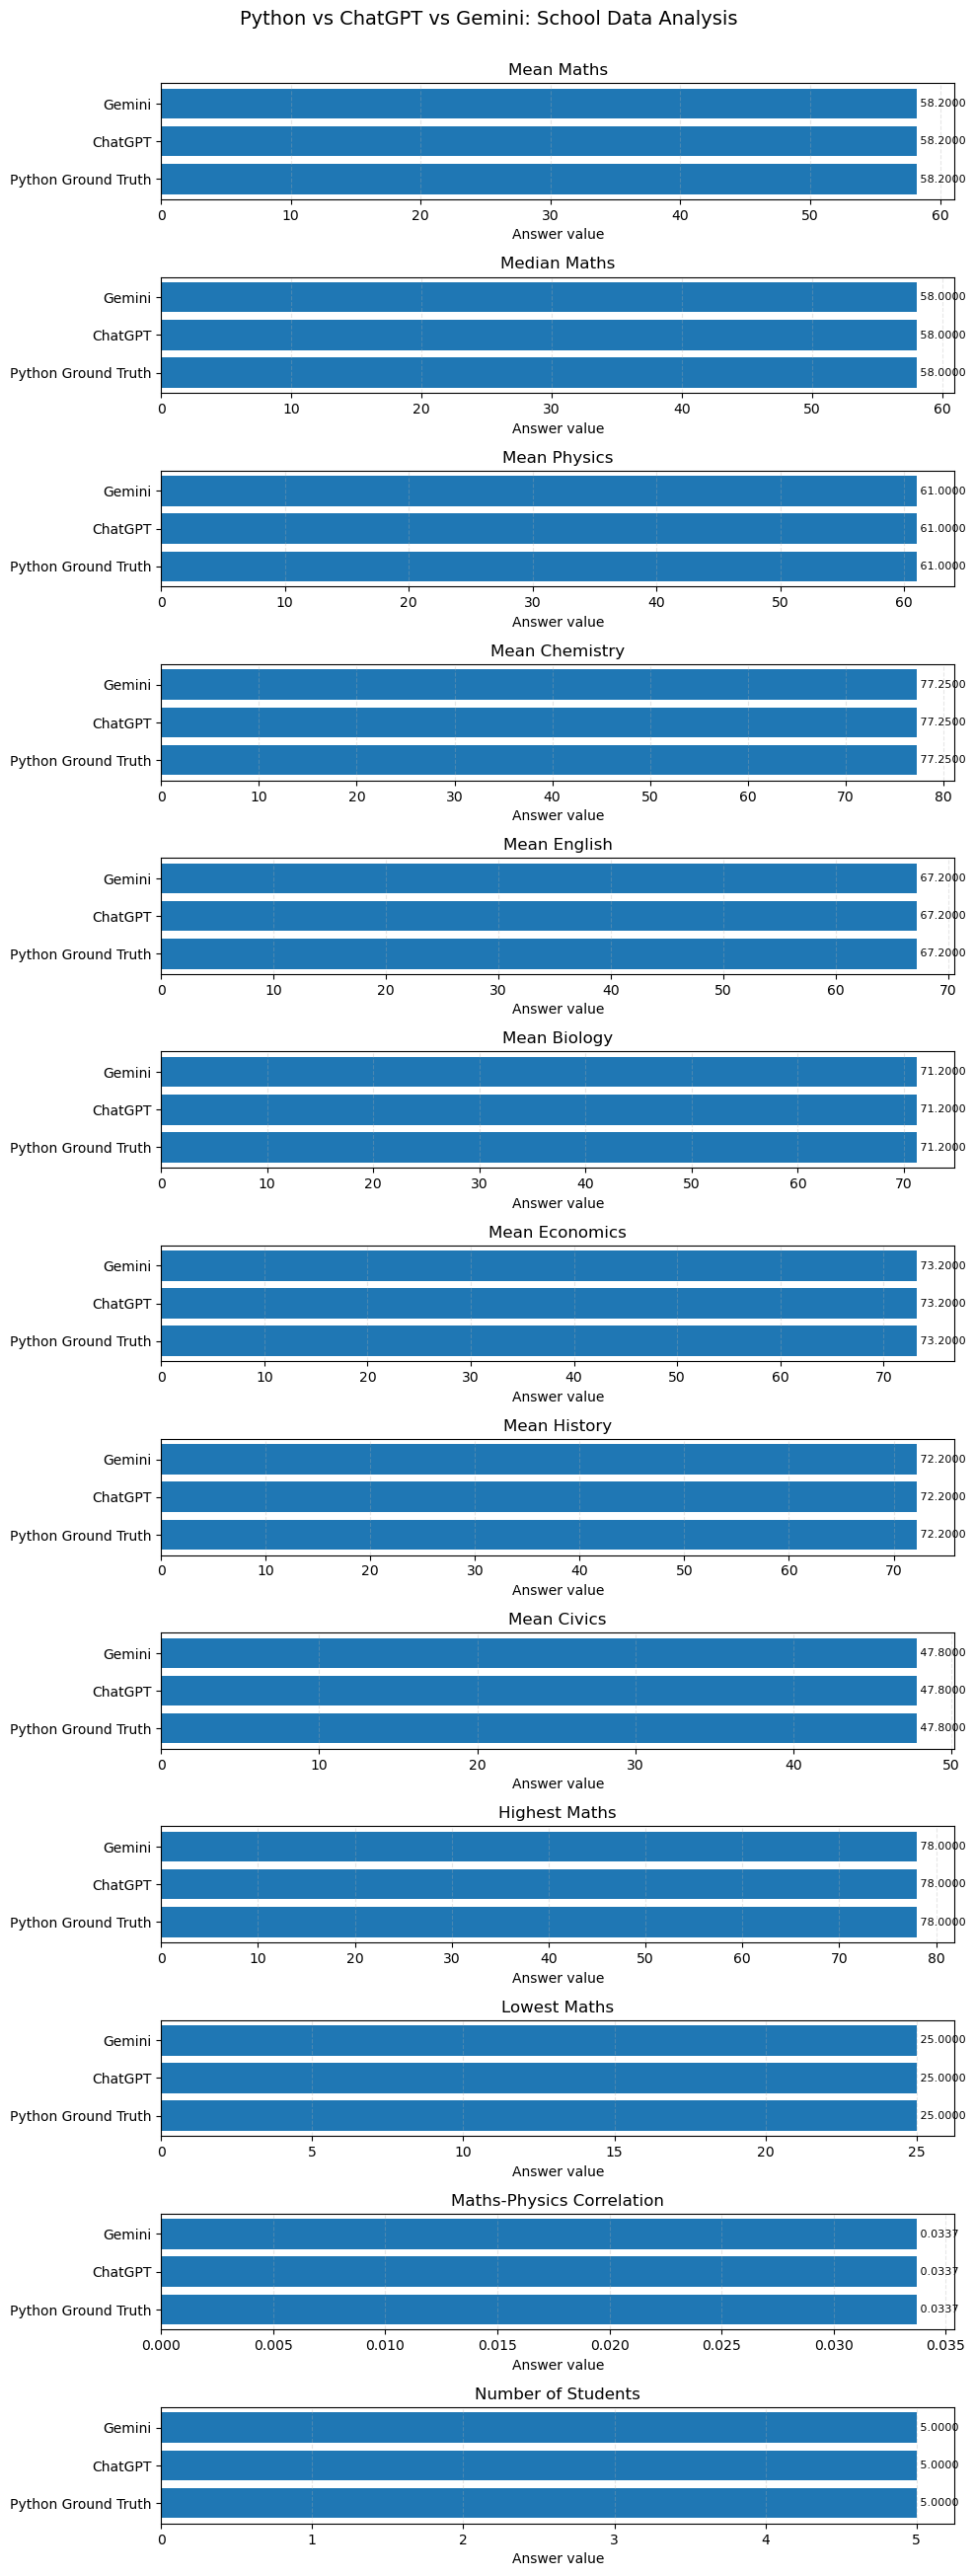

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("school_llm_comparison_results.csv")

models = ["Python_Ground_Truth", "ChatGPT_Answer", "Gemini_Answer"]
labels = ["Python Ground Truth", "ChatGPT", "Gemini"]

for col in models:
    df[col] = pd.to_numeric(df[col], errors="coerce")

n = len(df)
fig, axes = plt.subplots(n, 1, figsize=(10, max(20, n * 2.0)))
axes = np.atleast_1d(axes)

for ax, (_, row) in zip(axes, df.iterrows()):
    values = [row[col] for col in models]
    valid = [(label, value) for label, value in zip(labels, values)
             if pd.notna(value)]

    if valid:
        ax.barh(
            [item[0] for item in valid],
            [item[1] for item in valid]
        )
        for i, (_, value) in enumerate(valid):
            ax.text(value, i, f" {value:.4f}", va="center", fontsize=8)

    ax.set_title(row["Question"])
    ax.set_xlabel("Answer value")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle("Python vs ChatGPT vs Gemini: School Data Analysis",
             fontsize=14, y=1.002)
plt.tight_layout()
plt.savefig("school_answer_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


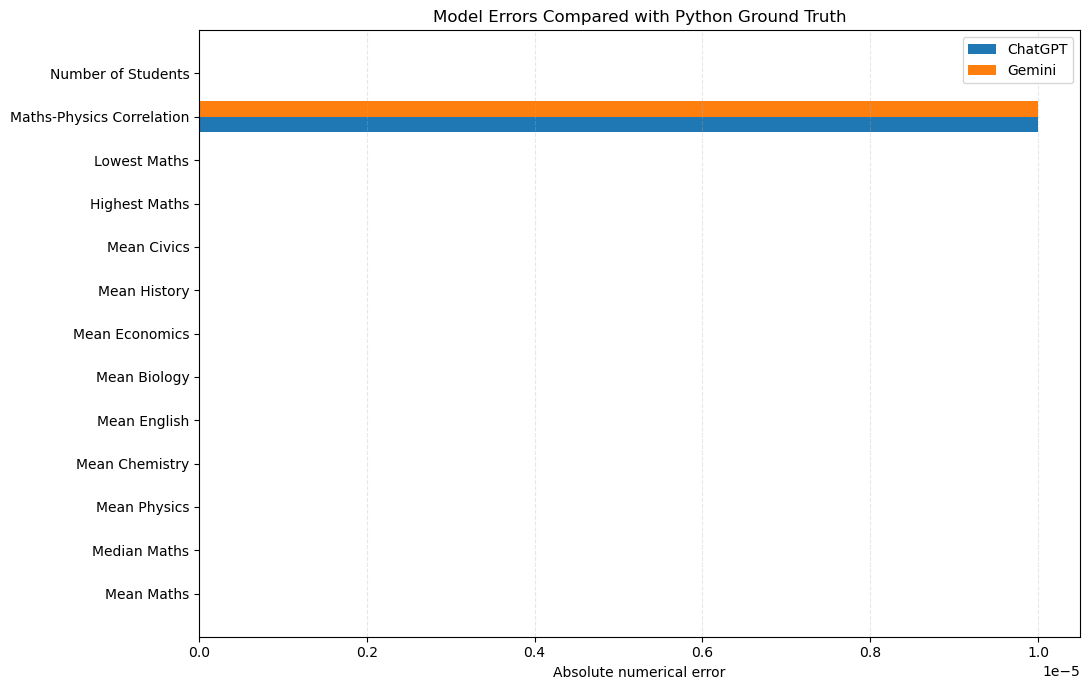

In [5]:

# Calculate absolute errors
df["ChatGPT_Error"] = (
    df["ChatGPT_Answer"] - df["Python_Ground_Truth"]
).abs()

df["Gemini_Error"] = (
    df["Gemini_Answer"] - df["Python_Ground_Truth"]
).abs()

# Keep questions where at least one model has a numerical answer
errors = df[
    df["ChatGPT_Error"].notna() | df["Gemini_Error"].notna()
].copy()

y = np.arange(len(errors))
height = 0.36

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    y - height / 2,
    errors["ChatGPT_Error"],
    height,
    label="ChatGPT"
)
ax.barh(
    y + height / 2,
    errors["Gemini_Error"],
    height,
    label="Gemini"
)

ax.set_yticks(y)
ax.set_yticklabels(errors["Question"])
ax.set_xlabel("Absolute numerical error")
ax.set_title("Model Errors Compared with Python Ground Truth")
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("school_absolute_errors.png", dpi=300, bbox_inches="tight")
plt.show()


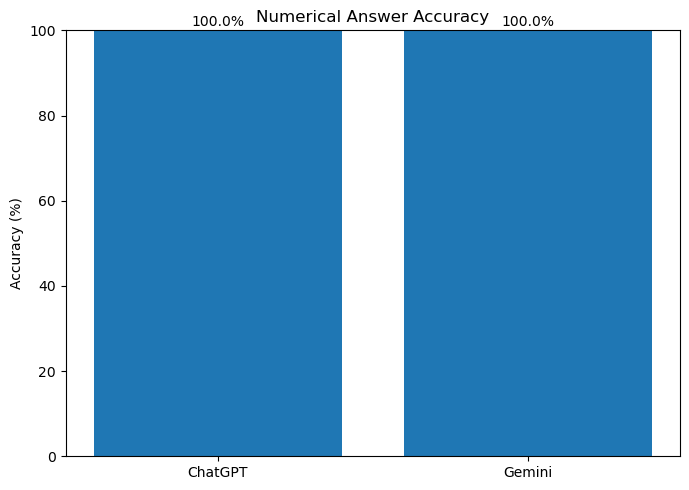

ChatGPT accuracy: 100.00%
Gemini accuracy: 100.00%


In [6]:

# Determine matches using a tolerance of 0.01
# The student count must match exactly.
def is_correct(row, model):
    answer = row[f"{model}_Answer"]
    truth = row["Python_Ground_Truth"]

    if pd.isna(answer) or pd.isna(truth):
        return np.nan

    if row["Question"] == "Number of Students":
        return int(answer == truth)

    return int(np.isclose(answer, truth, atol=0.01, rtol=0))

accuracies = {}

for model in ["ChatGPT", "Gemini"]:
    results = df.apply(lambda row: is_correct(row, model), axis=1)
    evaluated = results.dropna()
    accuracies[model] = (
        evaluated.mean() * 100 if len(evaluated) else np.nan
    )

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(list(accuracies.keys()), list(accuracies.values()))

ax.set_title("Numerical Answer Accuracy")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)

for bar, value in zip(bars, accuracies.values()):
    if pd.notna(value):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1,
            f"{value:.1f}%",
            ha="center"
        )

plt.tight_layout()
plt.savefig("school_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

for model, value in accuracies.items():
    print(f"{model} accuracy: {value:.2f}%" if pd.notna(value)
          else f"{model}: no answers available")



In [7]:

# Save errors and accuracy results together
df.to_csv("school_llm_comparison_results.csv", index=False)

accuracy_summary = pd.DataFrame([
    {
        "Model": model,
        "Accuracy_Percent": value,
        "Questions_Evaluated": int(
            df.apply(lambda row: is_correct(row, model), axis=1).notna().sum()
        )
    }
    for model, value in accuracies.items()
])

accuracy_summary.to_csv("school_model_accuracy_summary.csv", index=False)

display(accuracy_summary)
print("All graphs and CSV results have been saved.")


,Model,Accuracy_Percent,Questions_Evaluated
0,ChatGPT,100.0,13
1,Gemini,100.0,13


All graphs and CSV results have been saved.
